In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Loading Data

In [3]:
df = pd.read_csv('datasaurus.csv')
print(df.columns)
print()
print(df["dataset"].unique())  
print()
print(df["dataset"].value_counts())

Index(['dataset', 'x', 'y'], dtype='object')

['dino' 'away' 'h_lines' 'v_lines' 'x_shape' 'star' 'high_lines' 'dots'
 'circle' 'bullseye' 'slant_up' 'slant_down' 'wide_lines']

dino          142
away          142
h_lines       142
v_lines       142
x_shape       142
star          142
high_lines    142
dots          142
circle        142
bullseye      142
slant_up      142
slant_down    142
wide_lines    142
Name: dataset, dtype: int64


# Cleaning Data

In [4]:
print(df.isnull().sum())
df["x"] = df["x"].astype(np.float64)
df["y"] = df["y"].astype(np.float64)
df.info()

dataset    0
x          0
y          0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1846 entries, 0 to 1845
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dataset  1846 non-null   object 
 1   x        1846 non-null   float64
 2   y        1846 non-null   float64
dtypes: float64(2), object(1)
memory usage: 43.4+ KB


# Computing mean, variance, Pearson correlation and the least-squares line

In [6]:
def compute_mean(arr: np.ndarray) -> float:
    return np.sum(arr) / len(arr)


def compute_sample_variance(arr: np.ndarray, mean_val: float) -> float:
    return np.sum((arr - mean_val) ** 2) / (len(arr) - 1)


def compute_correlation(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> float:
    numerator = np.sum((x - mean_x) * (y - mean_y))
    denominator = np.sqrt(np.sum((x - mean_x) ** 2) * np.sum((y - mean_y) ** 2) )
    return numerator / denominator


def compute_linear_regression(
    x: np.ndarray, y: np.ndarray, mean_x: float, mean_y: float
) -> tuple[float, float]:
    beta_1 = np.sum((x - mean_x) * (y - mean_y)) / np.sum((x - mean_x) ** 2)
    beta_0 = mean_y - (beta_1 * mean_x)
    return beta_0, beta_1

# stats of df_x_shape

In [8]:
x_shape = df[df['dataset'] == 'x_shape']
x_shape

,dataset,x,y
568,x_shape,38.337757,92.472719
569,x_shape,35.751871,94.116768
570,x_shape,32.767218,88.518295
571,x_shape,33.729607,88.622266
572,x_shape,37.238249,83.724928
...,...,...,...
705,x_shape,34.794594,13.969683
706,x_shape,79.221764,22.094591
707,x_shape,36.030880,93.121733
708,x_shape,34.499558,86.609985


In [11]:
x_shape_mean_x = compute_mean(x_shape['x'])
x_shape_mean_y = compute_mean(x_shape['y'])
print(x_shape_mean_x, " ", x_shape_mean_y)

54.26015033403803   47.839717279160425


In [10]:
x_shape_pearson_xy = compute_correlation(x_shape["x"], x_shape['y'], x_shape_mean_x, x_shape_mean_y)
x_shape_pearson_xy

-0.0655833373100655

In [12]:
x_shape_slope = compute_linear_regression(x_shape["x"], x_shape['y'], x_shape_mean_x, x_shape_mean_y)
x_shape_slope

(53.55422625106995, -0.10531686581643593)

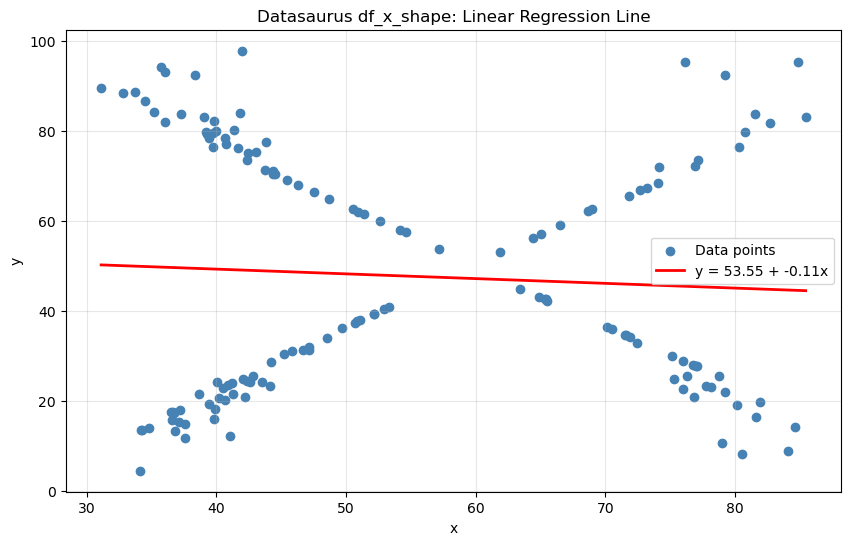

In [13]:
x_line = np.linspace(x_shape["x"].min(), x_shape["x"].max(), 100)
y_line = x_shape_slope[0] + x_shape_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(x_shape["x"], x_shape["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {x_shape_slope[0]:.2f} + {x_shape_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_x_shape: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_star

In [14]:
star = df[df['dataset'] == 'star']
star

,dataset,x,y
710,star,58.213608,91.881892
711,star,58.196054,92.214989
712,star,58.718231,90.310532
713,star,57.278373,89.907607
714,star,58.082020,92.008145
...,...,...,...
847,star,43.722551,19.077328
848,star,79.326078,52.900391
849,star,56.663974,87.940125
850,star,57.821789,90.693167


In [15]:
star_mean_x = compute_mean(star['x'])
star_mean_y = compute_mean(star['y'])
print(star_mean_x, " ", star_mean_y)

54.26734110449506   47.839545225097886


In [16]:
star_var_x = compute_sample_variance(star['x'], star_mean_x)
star_var_y = compute_sample_variance(star['y'], star_mean_y)
print(star_var_x, " ", star_var_y)

281.1979931971459   725.239694752202


In [17]:
star_pearson_xy = compute_correlation(star["x"], star['y'], star_mean_x, star_mean_y)
star_pearson_xy

-0.06296110022682307

In [18]:
star_slope = compute_linear_regression(star["x"], star['y'], star_mean_x, star_mean_y)
star_slope

(53.32667872603676, -0.10111299704868651)

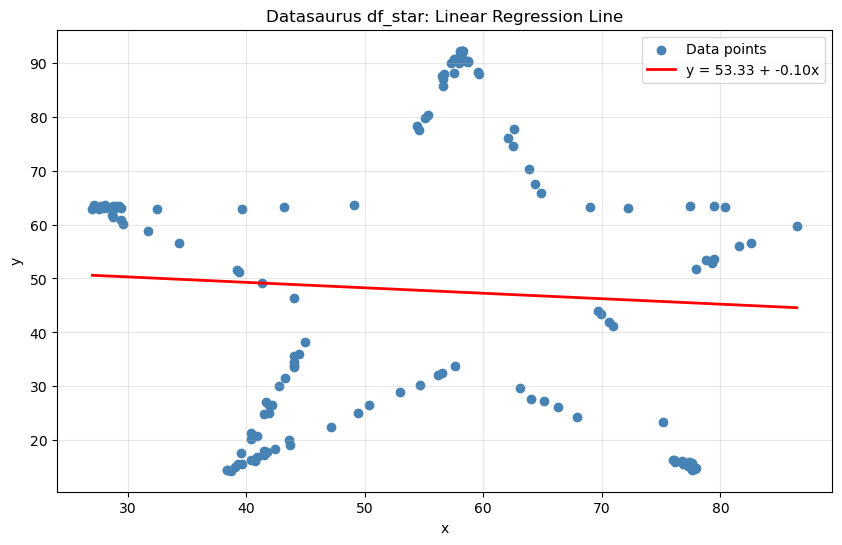

In [19]:
x_line = np.linspace(star["x"].min(), star["x"].max(), 100)
y_line = star_slope[0] + star_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(star["x"], star["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {star_slope[0]:.2f} + {star_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_star: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_high_lines

In [20]:
high_lines = df[df['dataset'] == 'high_lines']
high_lines

,dataset,x,y
852,high_lines,57.613234,83.905171
853,high_lines,51.274392,82.817983
854,high_lines,50.753898,76.754129
855,high_lines,37.021184,81.954470
856,high_lines,42.881755,80.184770
...,...,...,...
989,high_lines,37.949784,26.521749
990,high_lines,86.504391,34.894025
991,high_lines,50.815485,78.950839
992,high_lines,51.183467,85.128855


In [21]:
high_lines_mean_x = compute_mean(high_lines['x'])
high_lines_mean_y = compute_mean(high_lines['y'])
print(high_lines_mean_x, " ", high_lines_mean_y)

54.26880527974154   47.83545020393662


In [22]:
high_lines_var_x = compute_sample_variance(high_lines['x'], high_lines_mean_x)
high_lines_var_y = compute_sample_variance(high_lines['y'], high_lines_mean_y)
print(high_lines_var_x, " ", high_lines_var_y)

281.12236356582537   725.7634901501575


In [23]:
high_lines_pearson_xy = compute_correlation(high_lines["x"], high_lines['y'], high_lines_mean_x, high_lines_mean_y)
high_lines_pearson_xy

-0.06850422050586688

In [24]:
high_lines_slope = compute_linear_regression(high_lines["x"], high_lines['y'], high_lines_mean_x, high_lines_mean_y)
high_lines_slope

(53.808793163024305, -0.11006954968506605)

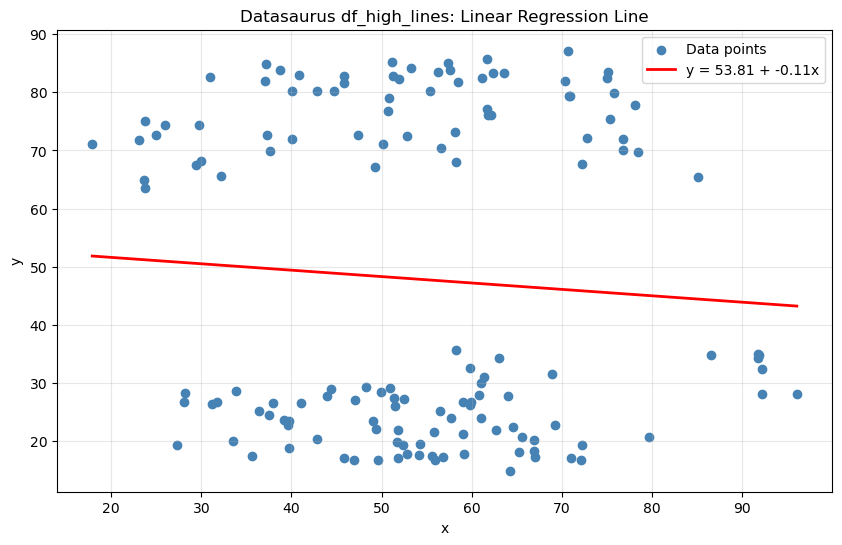

In [25]:
x_line = np.linspace(high_lines["x"].min(), high_lines["x"].max(), 100)
y_line = high_lines_slope[0] + high_lines_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(high_lines["x"], high_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {high_lines_slope[0]:.2f} + {high_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_high_lines: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_dots

In [26]:
dots = df[df['dataset'] == 'dots']
dots

,dataset,x,y
994,dots,51.147917,90.867412
995,dots,50.517126,89.102395
996,dots,50.207480,85.460047
997,dots,50.069482,83.057670
998,dots,50.562846,82.937822
...,...,...,...
1131,dots,50.533635,17.019581
1132,dots,77.500907,50.166986
1133,dots,50.691124,87.513960
1134,dots,49.990395,83.997357


In [27]:
dots_mean_x = compute_mean(dots['x'])
dots_mean_y = compute_mean(dots['y'])
print(dots_mean_x, " ", dots_mean_y)

54.26030345121761   47.83982920875564


In [28]:
dots_var_x = compute_sample_variance(dots['x'], dots_mean_x)
dots_var_y = compute_sample_variance(dots['y'], dots_mean_y)
print(dots_var_x, " ", dots_var_y)

281.15695341004164   725.2352152007652


In [29]:
dots_pearson_xy = compute_correlation(dots["x"], dots['y'], dots_mean_x, dots_mean_y)
dots_pearson_xy

-0.060341441993538594

In [30]:
dots_slope = compute_linear_regression(dots["x"], dots['y'], dots_mean_x, dots_mean_y)
dots_slope

(53.098341946502245, -0.09691270419219528)

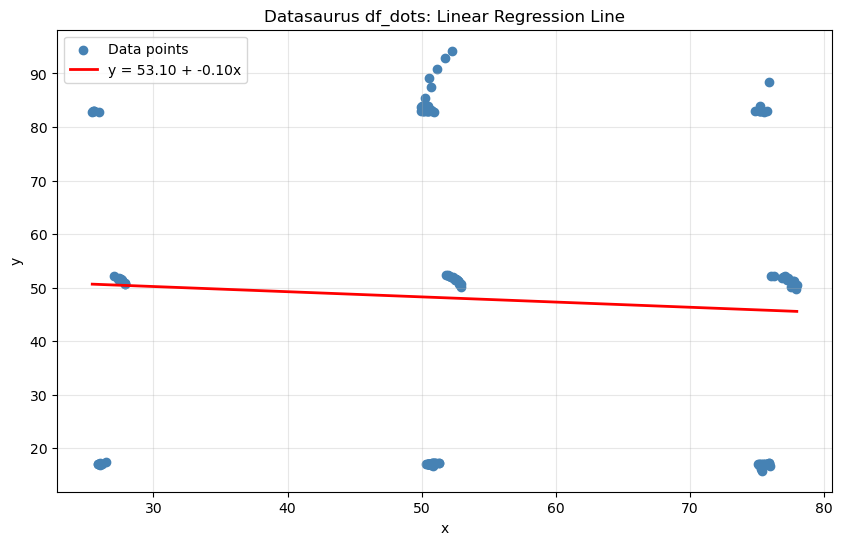

In [31]:
x_line = np.linspace(dots["x"].min(), dots["x"].max(), 100)
y_line = dots_slope[0] + dots_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(dots["x"], dots["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {dots_slope[0]:.2f} + {dots_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_dots: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_circle

In [32]:
circle = df[df['dataset'] == 'circle']
circle

,dataset,x,y
1136,circle,55.993030,79.277264
1137,circle,50.032254,79.013071
1138,circle,51.288459,82.435940
1139,circle,51.170537,79.165294
1140,circle,44.377915,78.164628
...,...,...,...
1273,circle,39.921363,19.701850
1274,circle,84.794278,55.568650
1275,circle,55.662959,83.356480
1276,circle,50.492248,78.997532


In [33]:
circle_mean_x = compute_mean(circle['x'])
circle_mean_y = compute_mean(circle['y'])
print(circle_mean_x, " ", circle_mean_y)

54.267319706173936   47.83771726721831


In [34]:
circle_var_x = compute_sample_variance(circle['x'], circle_mean_x)
circle_var_y = compute_sample_variance(circle['y'], circle_mean_y)
print(circle_var_x, " ", circle_var_y)

280.89802435237243   725.2268436918446


In [35]:
circle_pearson_xy = compute_correlation(circle["x"], circle['y'], circle_mean_x, circle_mean_y)
circle_pearson_xy

-0.06834335645012027

In [36]:
circle_slope = compute_linear_regression(circle["x"], circle['y'], circle_mean_x, circle_mean_y)
circle_slope

(53.79704498505452, -0.10981429984201387)

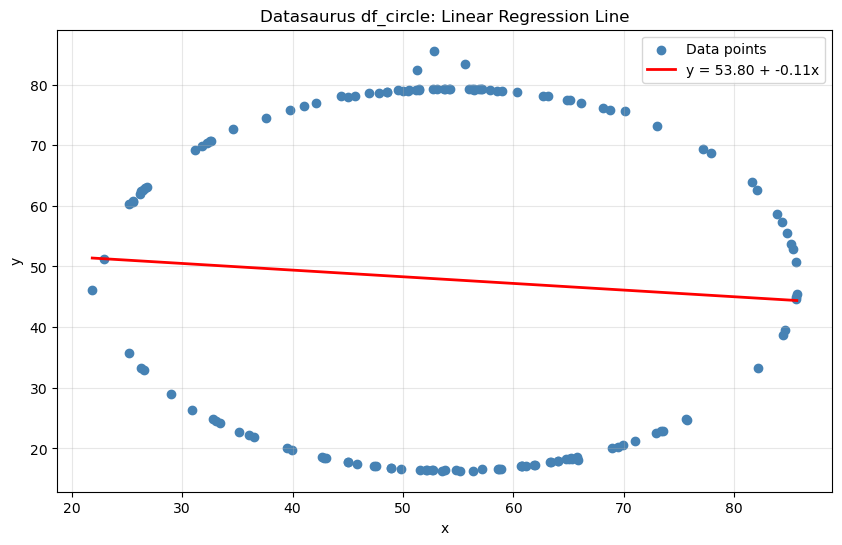

In [37]:
x_line = np.linspace(circle["x"].min(), circle["x"].max(), 100)
y_line = circle_slope[0] + circle_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(circle["x"], circle["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {circle_slope[0]:.2f} + {circle_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_circle: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_bullseye

In [38]:
bullseye = df[df['dataset'] == 'bullseye']
bullseye

,dataset,x,y
1278,bullseye,51.203891,83.339777
1279,bullseye,58.974470,85.499818
1280,bullseye,51.872073,85.829738
1281,bullseye,48.179931,85.045117
1282,bullseye,41.683200,84.017941
...,...,...,...
1415,bullseye,50.967748,29.679774
1416,bullseye,91.191054,46.674343
1417,bullseye,55.863768,85.336487
1418,bullseye,49.280595,84.048823


In [39]:
bullseye_mean_x = compute_mean(bullseye['x'])
bullseye_mean_y = compute_mean(bullseye['y'])
print(bullseye_mean_x, " ", bullseye_mean_y)

54.268730022378875   47.830823155217814


In [40]:
bullseye_var_x = compute_sample_variance(bullseye['x'], bullseye_mean_x)
bullseye_var_y = compute_sample_variance(bullseye['y'], bullseye_mean_y)
print(bullseye_var_x, " ", bullseye_var_y)

281.2073931879034   725.5333723122342


In [41]:
bullseye_pearson_xy = compute_correlation(bullseye["x"], bullseye['y'], bullseye_mean_x, bullseye_mean_y)
bullseye_pearson_xy

-0.06858639425794842

In [42]:
bullseye_slope = compute_linear_regression(bullseye["x"], bullseye['y'], bullseye_mean_x, bullseye_mean_y)
bullseye_slope

(53.80947081136491, -0.11016745101058519)

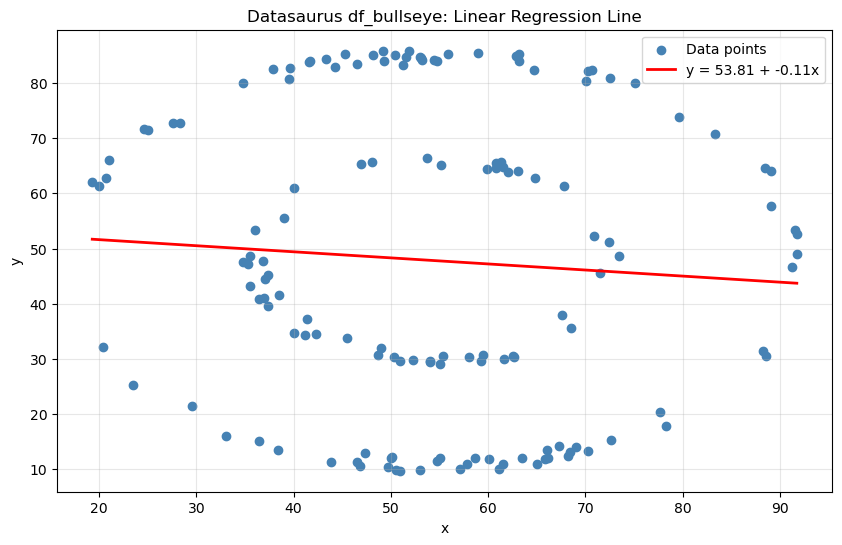

In [43]:
x_line = np.linspace(bullseye["x"].min(), bullseye["x"].max(), 100)
y_line = bullseye_slope[0] + bullseye_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(bullseye["x"], bullseye["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {bullseye_slope[0]:.2f} + {bullseye_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_bullseye: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_slant_up

In [44]:
slant_up = df[df['dataset'] == 'slant_up']
slant_up

,dataset,x,y
1420,slant_up,47.695201,95.241187
1421,slant_up,44.609976,93.075835
1422,slant_up,43.856381,94.085872
1423,slant_up,41.578929,90.303567
1424,slant_up,49.177419,96.610532
...,...,...,...
1557,slant_up,31.333244,32.538569
1558,slant_up,86.401550,38.746933
1559,slant_up,47.442112,98.184302
1560,slant_up,46.264741,94.116192


In [45]:
slant_up_mean_x = compute_mean(slant_up['x'])
slant_up_mean_y = compute_mean(slant_up['y'])
print(slant_up_mean_x, " ", slant_up_mean_y)

54.26588178560211   47.83149565202444


In [46]:
slant_up_var_x = compute_sample_variance(slant_up['x'], slant_up_mean_x)
slant_up_var_y = compute_sample_variance(slant_up['y'], slant_up_mean_y)
print(slant_up_var_x, " ", slant_up_var_y)

281.19441988924456   725.6886047971409


In [47]:
slant_up_pearson_xy = compute_correlation(slant_up["x"], slant_up['y'], slant_up_mean_x, slant_up_mean_y)
slant_up_pearson_xy

-0.06860920644502215

In [48]:
slant_up_slope = compute_linear_regression(slant_up["x"], slant_up['y'], slant_up_mean_x, slant_up_mean_y)
slant_up_slope

(53.81259564798683, -0.11021842452672188)

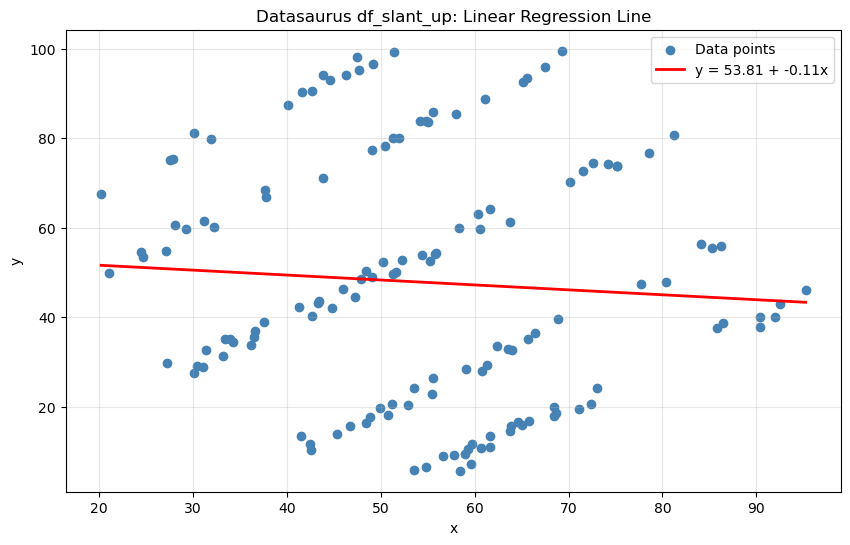

In [49]:
x_line = np.linspace(slant_up["x"].min(), slant_up["x"].max(), 100)
y_line = slant_up_slope[0] + slant_up_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(slant_up["x"], slant_up["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {slant_up_slope[0]:.2f} + {slant_up_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_slant_up: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_slant_down

In [50]:
slant_down = df[df['dataset'] == 'slant_down']
slant_down

,dataset,x,y
1562,slant_down,52.872021,97.343223
1563,slant_down,59.014144,93.574875
1564,slant_down,56.375109,96.305148
1565,slant_down,37.839200,94.359444
1566,slant_down,39.885373,90.634662
...,...,...,...
1699,slant_down,39.596501,32.136132
1700,slant_down,95.593416,33.234129
1701,slant_down,52.772288,99.613472
1702,slant_down,53.178614,98.603861


In [51]:
slant_down_mean_x = compute_mean(slant_down['x'])
slant_down_mean_y = compute_mean(slant_down['y'])
print(slant_down_mean_x, " ", slant_down_mean_y)

54.2678488233662   47.835896330588206


In [52]:
slant_down_var_x = compute_sample_variance(slant_down['x'], slant_down_mean_x)
slant_down_var_y = compute_sample_variance(slant_down['y'], slant_down_mean_y)
print(slant_down_var_x, " ", slant_down_var_y)

281.12420560037276   725.5537488881993


In [53]:
slant_down_pearson_xy = compute_correlation(slant_down["x"], slant_down['y'], slant_down_mean_x, slant_down_mean_y)
slant_down_pearson_xy

-0.06897973536063173

In [54]:
slant_down_slope = compute_linear_regression(slant_down["x"], slant_down['y'], slant_down_mean_x, slant_down_mean_y)
slant_down_slope

(53.849707743907686, -0.11081720657278205)

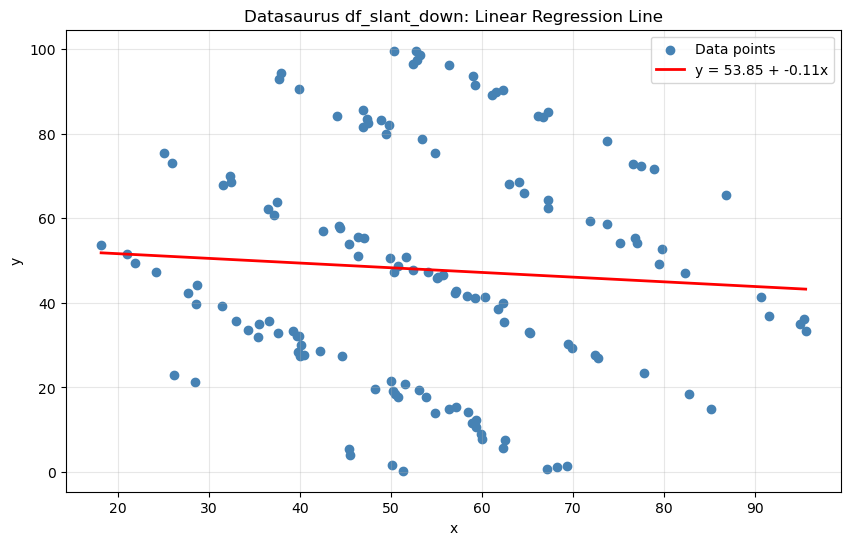

In [55]:
x_line = np.linspace(slant_down["x"].min(), slant_down["x"].max(), 100)
y_line = slant_down_slope[0] + slant_down_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(slant_down["x"], slant_down["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {slant_down_slope[0]:.2f} + {slant_down_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_slant_down: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# stats of df_wide_lines

In [56]:
wide_lines = df[df['dataset'] == 'wide_lines']
wide_lines

,dataset,x,y
1704,wide_lines,65.815540,95.588374
1705,wide_lines,65.672265,91.933402
1706,wide_lines,39.002716,92.261838
1707,wide_lines,37.795303,93.532455
1708,wide_lines,35.513901,89.599190
...,...,...,...
1841,wide_lines,33.674442,26.090490
1842,wide_lines,75.627255,37.128752
1843,wide_lines,40.610125,89.136240
1844,wide_lines,39.114366,96.481751


In [57]:
wide_lines_mean_x = compute_mean(wide_lines['x'])
wide_lines_mean_y = compute_mean(wide_lines['y'])
print(wide_lines_mean_x, " ", wide_lines_mean_y)

54.266916301257034   47.831601988006156


In [58]:
wide_lines_var_x = compute_sample_variance(wide_lines['x'], wide_lines_mean_x)
wide_lines_var_y = compute_sample_variance(wide_lines['y'], wide_lines_mean_y)
print(wide_lines_var_x, " ", wide_lines_var_y)

281.2328871866248   725.6505602672039


In [59]:
wide_lines_pearson_xy = compute_correlation(wide_lines["x"], wide_lines['y'], wide_lines_mean_x, wide_lines_mean_y)
wide_lines_pearson_xy

-0.06657523019998104

In [60]:
wide_lines_slope = compute_linear_regression(wide_lines["x"], wide_lines['y'], wide_lines_mean_x, wide_lines_mean_y)
wide_lines_slope

(53.63494893503815, -0.10694079086446209)

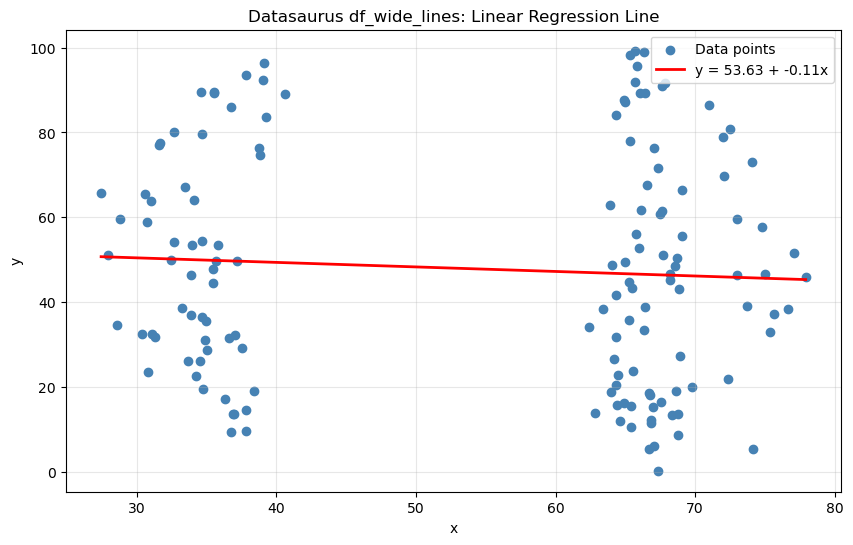

In [61]:
x_line = np.linspace(wide_lines["x"].min(), wide_lines["x"].max(), 100)
y_line = wide_lines_slope[0] + wide_lines_slope[1] * x_line
plt.figure(figsize=(10, 6))
plt.scatter(wide_lines["x"], wide_lines["y"], color="steelblue", label="Data points")
plt.plot(x_line, y_line, color="red", linewidth=2, label=f"y = {wide_lines_slope[0]:.2f} + {wide_lines_slope[1]:.2f}x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Datasaurus df_wide_lines: Linear Regression Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()